# 03 - Statistical analysis (in-sample)
HAC regressions, multiple-testing control, ADF, Granger, rolling correlations. In-sample significance is *not* evidence of tradability.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
R = ROOT / 'results'

In [2]:
for s in ('zc','zs'):
    t = pd.read_csv(R/f'regression_results/univariate_primary_{s}.csv')
    print(s); display(t.sort_values('p_hac').head(8)[['feature','horizon','n','start','beta','t_hac','p_hac','p_bh','r2']].round(4))

zc


,feature,horizon,n,start,beta,t_hac,p_hac,p_bh,r2
2,aar_grain_carloads__anomz,1,213,2020-04-10,0.0060,3.6041,0.0003,0.0139,0.0442
17,aar_grain_carloads__anomz,2,182,2020-04-10,0.0090,3.4242,0.0006,0.0139,0.0597
32,aar_grain_carloads__anomz,4,126,2020-05-01,0.0112,2.7736,0.0055,0.0832,0.0663
1,us_railcars__anomz,1,360,2018-04-06,0.0042,2.5975,0.0094,0.1056,0.0184
41,cost_gulf_vessel__anomz,4,446,2007-03-02,0.0118,2.1854,0.0289,0.2597,0.0256
37,sales_com_net_sales__anomz,4,478,2008-01-25,0.0069,2.0281,0.0426,0.2613,0.0139
16,us_railcars__anomz,2,310,2018-04-06,0.0057,2.0088,0.0446,0.2613,0.0196
6,sales_com_exports__anomz,1,792,2008-01-25,0.0018,1.8563,0.0634,0.2613,0.0040


zs


,feature,horizon,n,start,beta,t_hac,p_hac,p_bh,r2
17,aar_grain_carloads__anomz,2,194,2020-04-10,0.0075,3.6603,0.0003,0.0066,0.0625
2,aar_grain_carloads__anomz,1,226,2020-04-10,0.0044,3.6210,0.0003,0.0066,0.0383
0,ia_railcars__anomz,1,374,2017-12-15,0.0038,3.1198,0.0018,0.0271,0.0214
30,ia_railcars__anomz,4,226,2017-12-15,0.0135,2.9424,0.0033,0.0366,0.0682
16,us_railcars__anomz,2,309,2018-04-06,0.0060,2.7201,0.0065,0.0532,0.0323
15,ia_railcars__anomz,2,321,2017-12-15,0.0063,2.6927,0.0071,0.0532,0.0326
1,us_railcars__anomz,1,360,2018-04-06,0.0033,2.5703,0.0102,0.0653,0.0167
31,us_railcars__anomz,4,218,2018-05-04,0.0110,2.2893,0.0221,0.1241,0.0552


In [3]:
print(open(R/'regression_results/multiple_regression_zs.txt').read()[:4000])

===== Soybeans: Iowa universe + controls (h=1) =====
                            OLS Regression Results                            
Dep. Variable:                  fwd_1   R-squared:                       0.112
Model:                            OLS   Adj. R-squared:                  0.047
Method:                 Least Squares   F-statistic:                     2.606
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           0.000382
Time:                        20:58:26   Log-Likelihood:                 637.68
No. Observations:                 283   AIC:                            -1235.
Df Residuals:                     263   BIC:                            -1162.
Df Model:                          19                                         
Covariance Type:                  HAC                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------

In [4]:
for s in ('zc','zs'):
    g = pd.read_csv(R/f'regression_results/granger_{s}.csv'); print(s); display(g.sort_values('p_value').head(6).round(4))

zc


,feature,lags,F,p_value,n,p_bh
32,cost_gulf_vessel__anomz,1,12.4858,0.0004,648,0.0193
6,aar_grain_carloads__anomz,1,8.0895,0.0050,176,0.1098
7,aar_grain_carloads__anomz,2,4.8191,0.0095,146,0.1386
25,cost_truck__anomz,4,3.1690,0.0139,404,0.1399
17,sales_com_exports__anomz,1,5.7264,0.0170,665,0.1399
14,insp_com_mt__anomz,1,5.5211,0.0191,669,0.1399


zs


,feature,lags,F,p_value,n,p_bh
0,ia_railcars__anomz,1,6.9961,0.0086,325,0.2385
6,aar_grain_carloads__anomz,1,6.6604,0.0106,196,0.2385
7,aar_grain_carloads__anomz,2,3.0675,0.0493,164,0.5627
3,us_railcars__anomz,1,3.8540,0.0505,313,0.5627
1,ia_railcars__anomz,2,2.6141,0.0751,273,0.5627
44,basis_gulf_com__anomz,4,2.0860,0.0824,332,0.5627


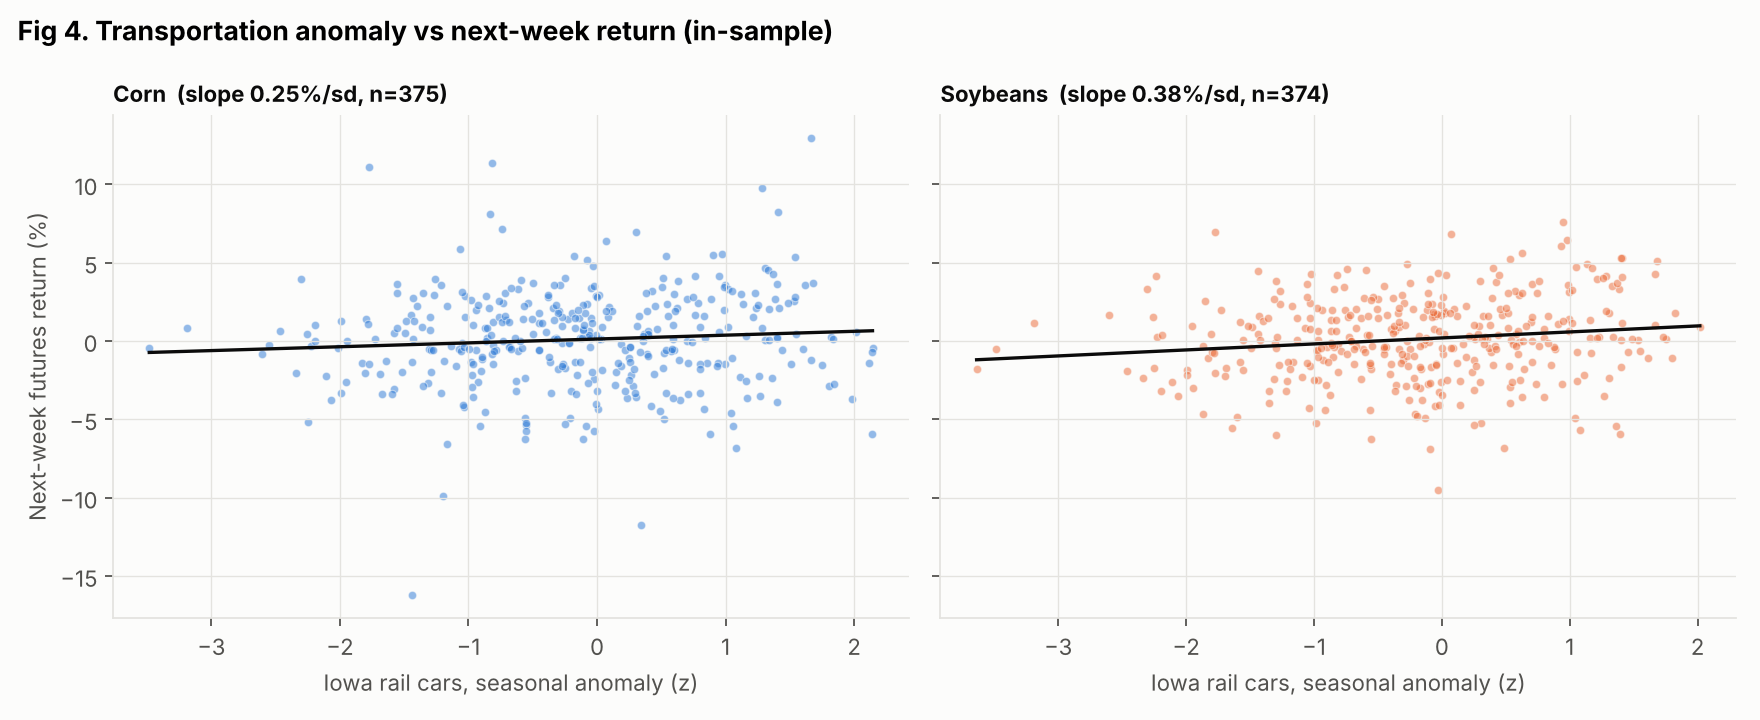

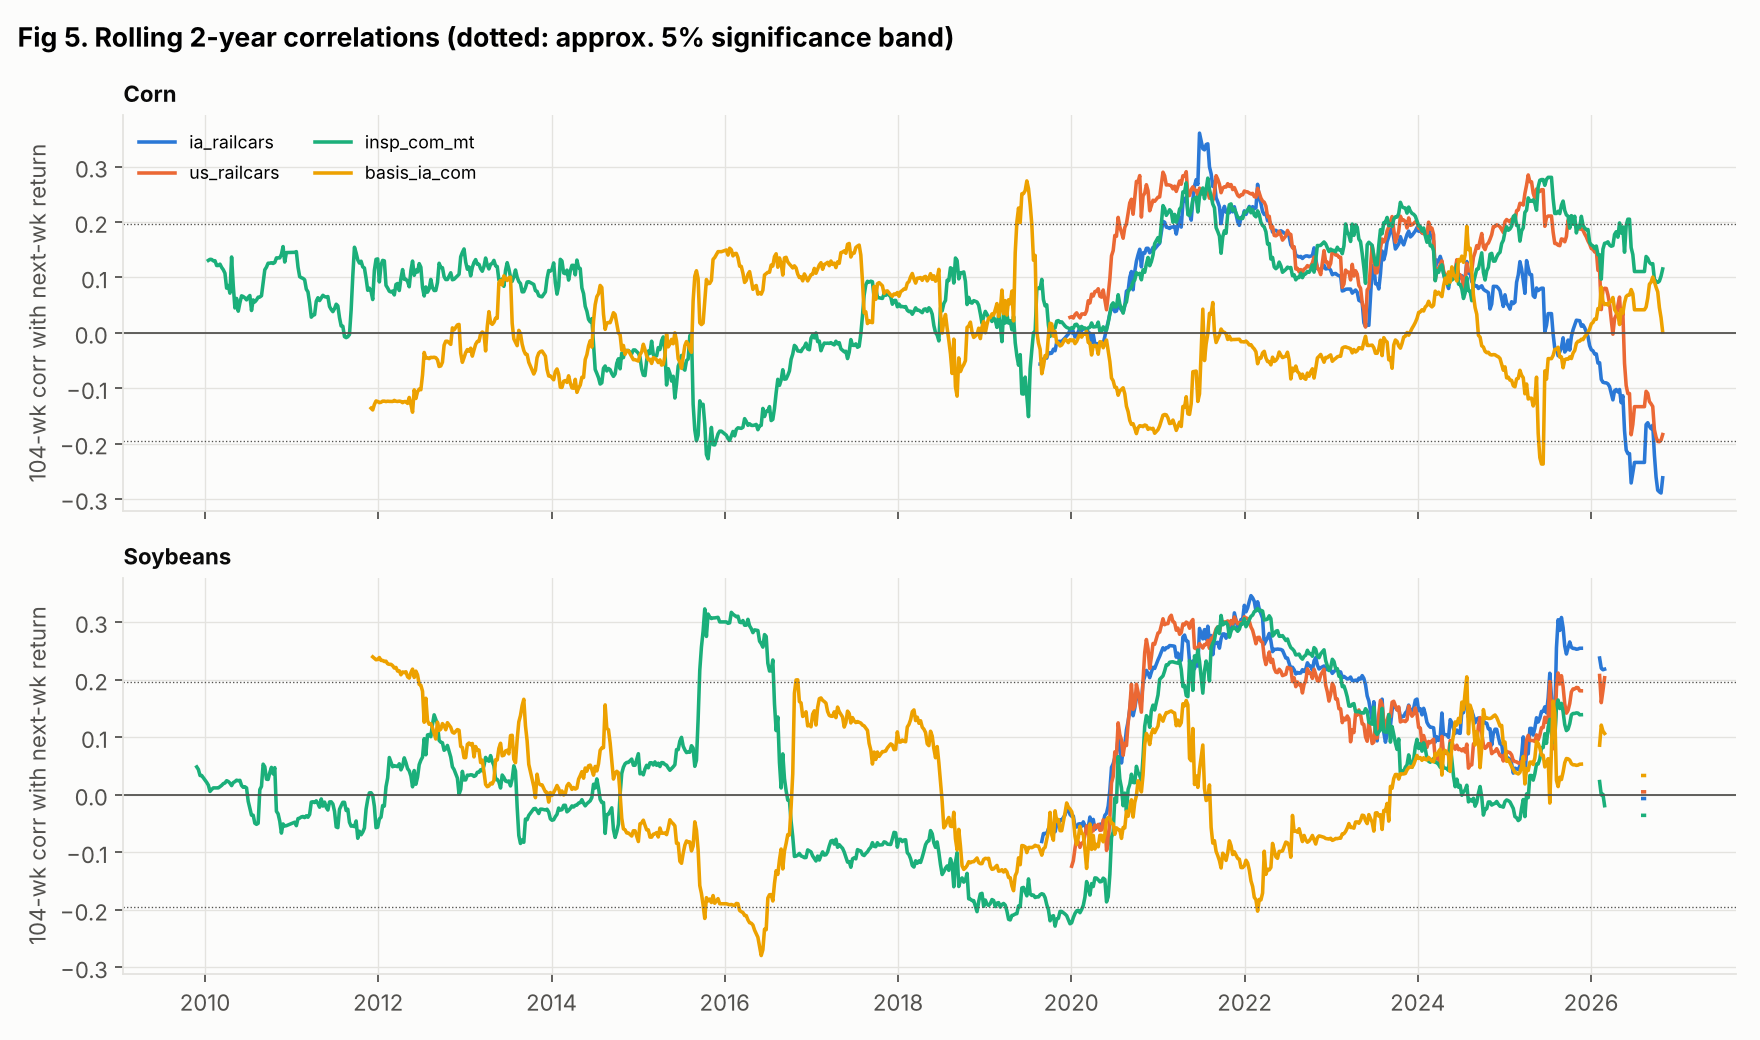

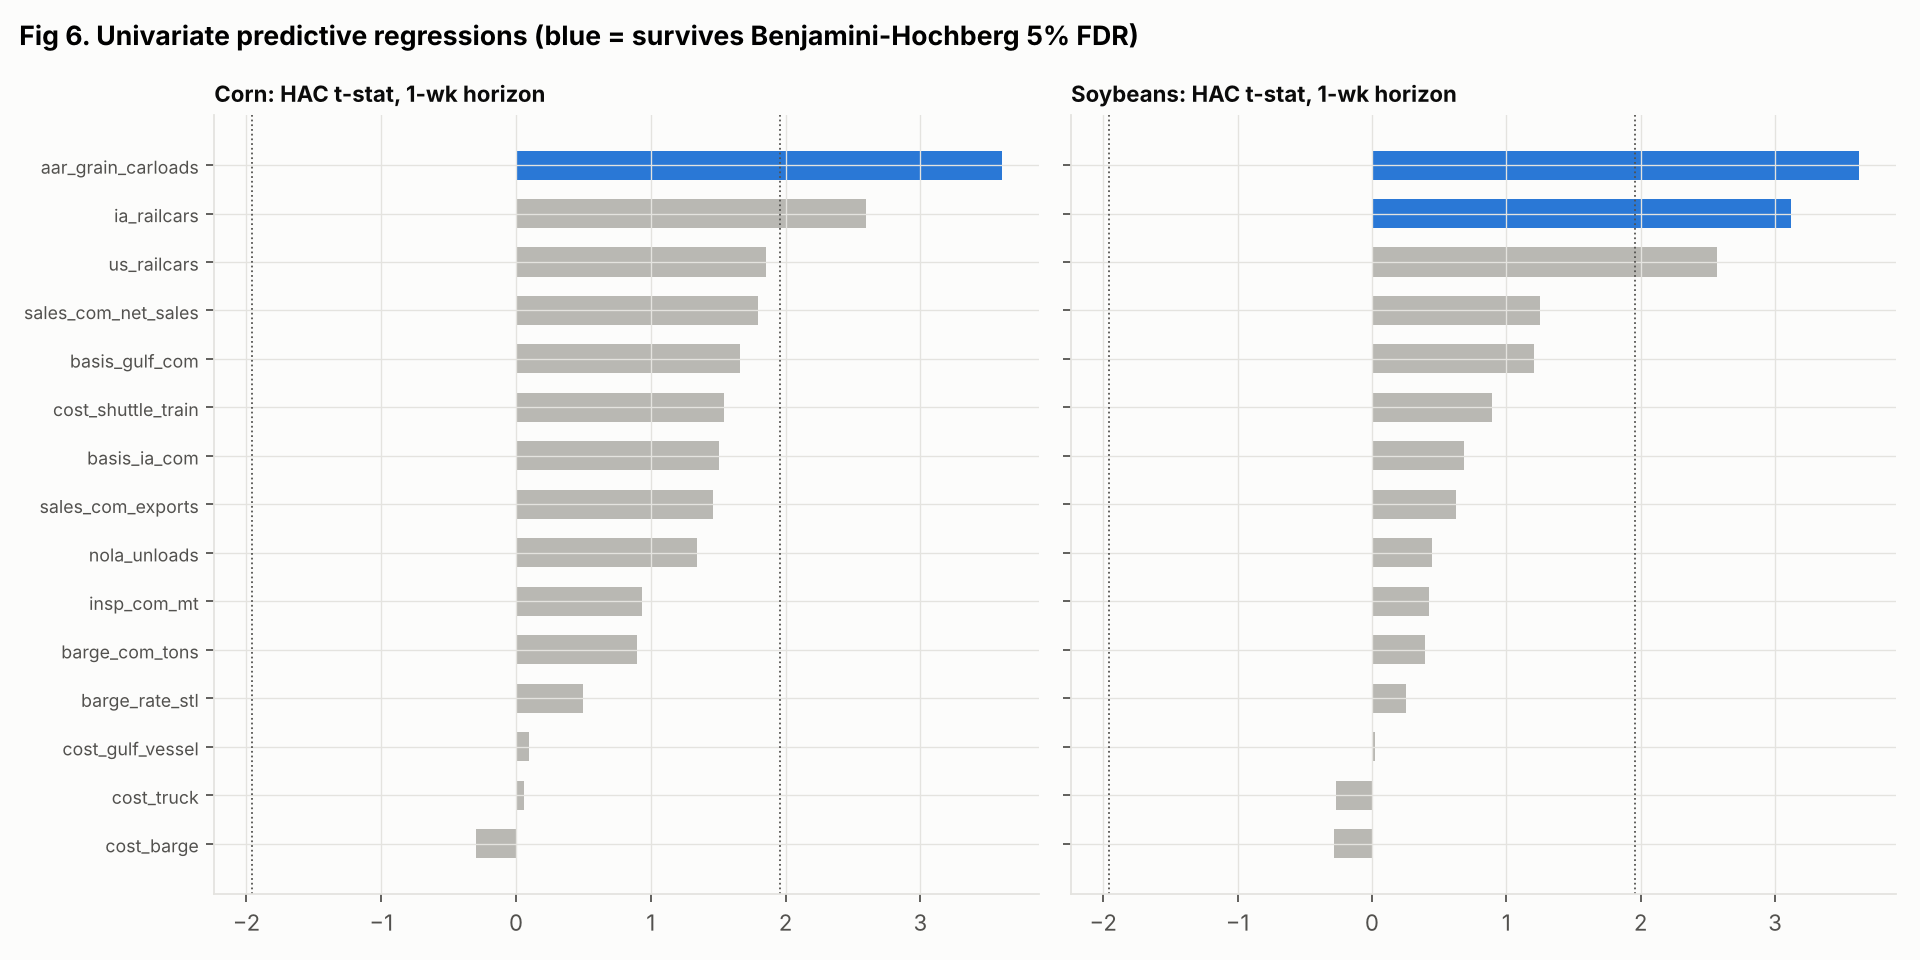

In [5]:
display(Image(R/'charts/04_transport_vs_returns.png'))
display(Image(R/'charts/05_rolling_correlations.png'))
display(Image(R/'charts/06_regression_tstats.png'))